# Calendar Year Tests: Per Diagonal or in Total

In [1]:
import numpy as np
import pandas as pd

import chainladder as cl

`ValuationCorrelation` tests Mack's assumption that no calendar year pushes
a whole diagonal of link ratios up or down. With `total=False` it tests
each diagonal on its own. With `total=True`, the default, it tests one
statistic summed over all diagonals. (`Triangle.valuation_correlation`
defaults to `total=False`.) This example applies both forms to one
triangle, then to samples of claims at three grains.

The test marks each link ratio L if it is larger than the median of its
development period and S if it is smaller. The median itself gets neither
mark. Here are the marks for the paid triangle in `tail_sample`, with `*`
for the medians:

In [2]:
paid = cl.load_sample("tail_sample")["paid"]
link_ratios = paid.link_ratio.to_frame(origin_as_datetime=False)
signs = np.sign(link_ratios - link_ratios.median())

# 1 marks a large link ratio (L), -1 a small one (S), 0 a median.
marks = paid.link_ratio
marks.values = signs.to_numpy()[None, None]


def cells_marked(mark):
    mask = marks.copy()
    mask.values = np.where(marks.values == mark, 1.0, np.nan)
    return mask


(
    marks.style
    .format({1: "L", -1: "S", 0: "*"}.get, na_rep="")
    .apply_from_triangle(cells_marked(1), color="#B2182B", text_color="white")
    .apply_from_triangle(cells_marked(-1), color="#2166AC", text_color="white")
)

,12-24,24-36,36-48,48-60,60-72,72-84,84-96,96-108,108-120
2000,L,S,S,S,S,S,L,L,*
2001,L,L,S,S,L,L,*,S,
2002,S,L,L,L,S,L,S,,
2003,L,S,*,S,L,S,,,
2004,S,L,L,L,*,,,,
2005,S,S,L,L,,,,,
2006,S,L,S,,,,,,
2007,*,S,,,,,,,
2008,L,,,,,,,,


The ratios that end in calendar year 2008 run from 2000 at 96-108 down to
2007 at 12-24. Six of them are L, two are medians and none is S. With no
calendar-year effect, six marks would all agree with probability 1 in 32,
about 0.03, so the per-diagonal test flags 2008 at the 10% level:

In [3]:
cl.ValuationCorrelation(paid, p_critical=0.1, total=False).z_critical

,2001,2002,2003,2004,2005,2006,2007,2008,2009
2000,False,False,False,False,False,False,False,True,False


The total test on the same triangle does not flag it:

In [4]:
cl.ValuationCorrelation(paid, p_critical=0.1, total=True).z_critical

columns,paid
Total,
Total,False


How much weight one flag deserves depends on how many diagonals were
tested, since each diagonal is a separate test at the 10% level. Grain
sets that number. The `prism` sample holds 34,244 claims with accident
dates from 2008 through 2017. Its paid triangle has 9 link-ratio diagonals
at annual grain, 19 at semiannual grain and 39 at quarterly grain. Split
the claims at random into 100 samples of 342 or 343 claims, then test each
sample's paid triangle at each grain:

In [5]:
claims = cl.load_sample("prism")["Paid"]
rng = np.random.default_rng(2026)
sample_of_claim = rng.permutation(claims.shape[0]) % 100
samples = claims.groupby(sample_of_claim).sum().incr_to_cum()

grains = {"Annual": "OYDY", "Semiannual": "OSDS", "Quarterly": "OQDQ"}
rows = []
for grain, code in grains.items():
    tri = samples.grain(code)
    per_diagonal = cl.ValuationCorrelation(tri, p_critical=0.1, total=False)
    total = cl.ValuationCorrelation(tri, p_critical=0.1, total=True)
    flags = per_diagonal.z_critical.values[:, 0, 0, :]
    rows.append({
        "Grain": grain,
        "Diagonals": flags.shape[1],
        "Most often flagged diagonal": flags.mean(axis=0).max(),
        "Any diagonal flagged": flags.any(axis=1).mean(),
        "Total test flagged": total.z_critical.values[:, 0].mean(),
    })
by_grain = pd.DataFrame(rows).set_index("Grain")
by_grain

,Diagonals,Most often flagged diagonal,Any diagonal flagged,Total test flagged
Grain,,,,
Annual,9,0.04,0.12,0.12
Semiannual,19,0.07,0.49,0.07
Quarterly,39,0.10,0.77,0.11


No diagonal is flagged in more than 10 of the 100 samples at any grain,
so no single period stands out. But each sample triangle gets one test
per diagonal, so the share of samples with at least one flagged diagonal
rises from 12% at annual grain to 49% at semiannual grain and 77% at
quarterly grain. The total test flags 7% to 12% of the samples at every
grain.

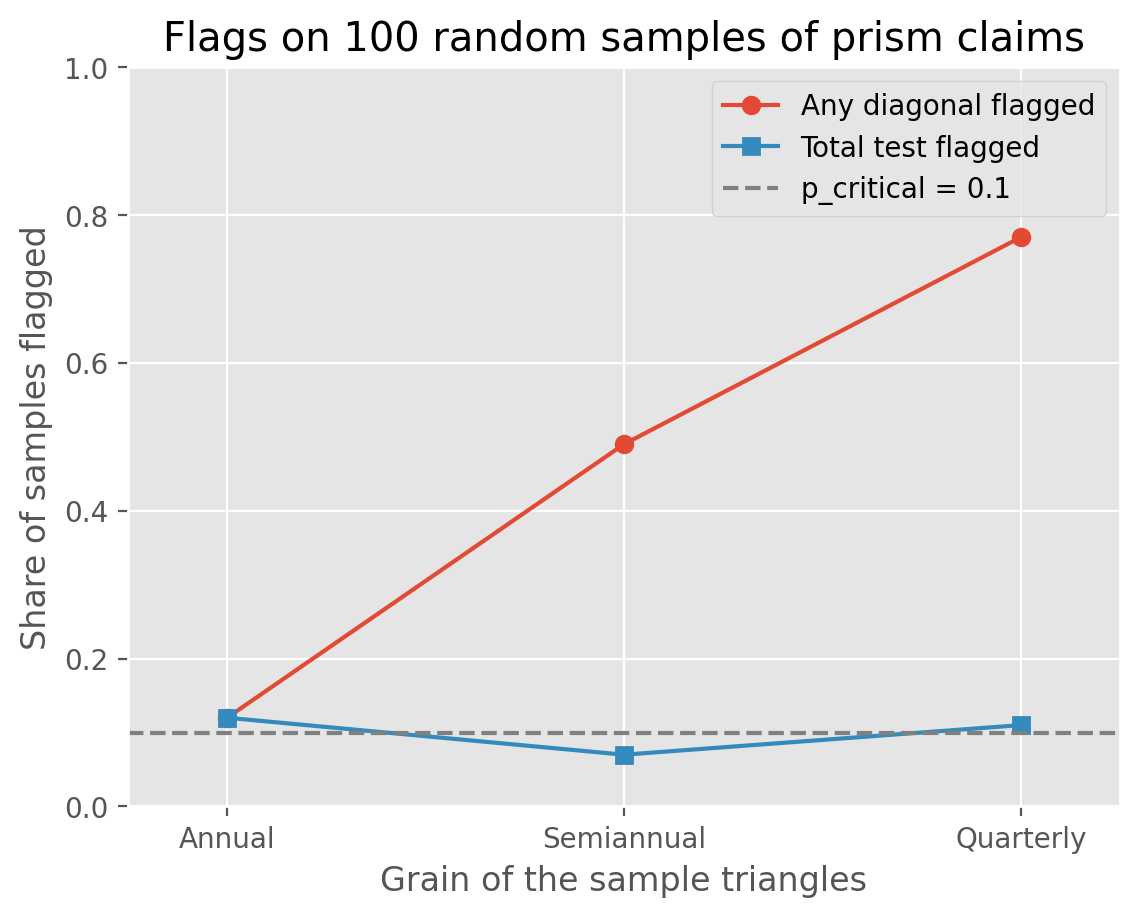

In [6]:
import matplotlib.pyplot as plt

plt.style.use("ggplot")
%config InlineBackend.figure_format = 'retina'

ax = by_grain[["Any diagonal flagged", "Total test flagged"]].plot(
    style=["o-", "s-"],
    xlim=(-0.25, 2.25),
    ylim=(0, 1),
    title="Flags on 100 random samples of prism claims",
    ylabel="Share of samples flagged",
    xlabel="Grain of the sample triangles",
)
ax.set_xticks(range(len(by_grain)), by_grain.index)
ax.axhline(0.1, color="grey", linestyle="--", label="p_critical = 0.1")
ax.legend();

A single `True` in the per-diagonal output is therefore weak evidence on
its own, and weaker at a finer grain. The annual samples have ten
accident years, like `tail_sample`, and 12 of the 100 have at least one
flagged diagonal. Mack tests the total for this reason, since testing
each diagonal separately lets the error probabilities accumulate
{cite}`mack1994`.